In [1]:
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [66]:
class McCullochPittsNeuron:
    """ McCulloch-Pitts neuron with fixed weights and threshold """

    def __init__(self, weights, threshold):
        """
        Initialize the neuron with fixed weights and threshold

        Parameters:
        weights (list): Synaptic weights
        threshold (float): Activation threshold
        """
        self.weights = np.array(weights)
        self.threshold = threshold

    def activate(self, inputs):
        """
        Activate the neuron for given inputs

        Parameters:
        inputs (list): Input values (binary)

        Returns:
        int: 1 if weighted sum >= threshold, else 0
        """
        weighted_sum = np.dot(inputs, self.weights)
        return 1 if weighted_sum >= self.threshold else 0

    def predict(self, X):
        """
        Predict outputs for multiple input samples

        Parameters:
        X (array-like): Matrix of input samples

        Returns:
        array: Predictions for all samples
        """
        return np.array([self.activate(x) for x in X])

In [32]:
def and_gate():
    return McCullochPittsNeuron([1,1],2)

In [33]:
and_neuron = and_gate()

In [67]:
print("AND Truth table")
print("A B | Output")
print("------------")
for A in [0,1]:
    for B in [0,1]:
        output = and_neuron.activate([A,B])
        print(f"{A} {B} | {output}")

AND Truth table
A B | Output
------------
0 0 | 0
0 1 | 0
1 0 | 0
1 1 | 1


In [68]:
def or_gate():
    return McCullochPittsNeuron([1,1],1)

In [69]:
or_neuron = or_gate()

In [70]:
print("OR Truth table")
print("A B | Output")
print("------------")
for A in [0,1]:
    for B in [0,1]:
        output = or_neuron.activate([A,B])
        print(f"{A} {B} | {output}")

OR Truth table
A B | Output
------------
0 0 | 0
0 1 | 1
1 0 | 1
1 1 | 1


In [71]:
def not_gate():
    return McCullochPittsNeuron([-1],0)

In [72]:
not_neuron = not_gate()

In [73]:
print("NOT Truth table")
print("A | Output")
print("------------")
for A in [0,1]:
    output = not_neuron.activate([A])
    print(f"{A}| {output}")

NOT Truth table
A | Output
------------
0| 1
1| 0


In [77]:
def nand_gate():
    return McCullochPittsNeuron([-1,-1],-1.5)

In [78]:
nand_neuron = nand_gate()

In [79]:
print("NAND Truth table")
print("A B | Output")
print("------------")
for A in [0,1]:
    for B in [0,1]:
        output = nand_neuron.activate([A,B])
        print(f"{A} {B} | {output}")

NAND Truth table
A B | Output
------------
0 0 | 1
0 1 | 1
1 0 | 1
1 1 | 0


In [80]:
def nor_gate():
    return McCullochPittsNeuron([-1,-1],0)

In [81]:
nor_neuron = nor_gate()

In [82]:
print("NOR Truth table")
print("A B | Output")
print("------------")
for A in [0,1]:
    for B in [0,1]:
        output = nor_neuron.activate([A,B])
        print(f"{A} {B} | {output}")

NOR Truth table
A B | Output
------------
0 0 | 1
0 1 | 0
1 0 | 0
1 1 | 0


In [49]:
class XORNetwork:
    """ Network of 3 McCulloch-Pitts neurons """

    def __init__(self):
        """
        Neuron 1: A AND NOT B
        """
        self.n1 = McCullochPittsNeuron([1,-1], 1)
        """
        Neuron 2: NOT A AND B
        """
        self.n2 = McCullochPittsNeuron([-1,1], 1)
        """
        Neuron 3: n1 OR n2
        """
        self.n3 = McCullochPittsNeuron([1,1], 1)

    def predict(self, X):
        """
        Parameters:
        X: list of inputs [A, B] that belong to {0,1}

        Returns:
        Result of XOR
        """
        output1 = self.n1.activate(X)
        output2 = self.n2.activate(X)
        output  = self.n3.activate([output1, output2])
        return output

    def evaluate(self):
        """
        Test all combinations
        """
        inputs = [[0,0], [0,1], [1,0], [1,1]]
        expected_results = [0, 1, 1, 0]
        print("XOR Evaluation")
        for input, result in zip(inputs, expected_results):
            pred = self.predict(input)
            status = "OK" if pred == result else "FAIL"
            print(f"{input[0]} XOR {input[1]} = {pred} {status}")

xor = XORNetwork()
xor.evaluate()

XOR Evaluation
0 XOR 0 = 0 OK
0 XOR 1 = 1 OK
1 XOR 0 = 1 OK
1 XOR 1 = 0 OK


In [56]:
"""
Demonstration: Why a single neuron cannot resolve the XOR
"""
print("A B  | Expected | Condition")
print("-----+----------+----------")
combinations = [(0,0,0), (0,1,1), (1,0,1), (1,1,0)]
for A, B, expected in combinations:
    if expected == 1:
        condition = f"w1*{A} + w2*{B} >= theta"
    else:
        condition = f"w1*{A} + w2*{B} < theta"
    print(f"{A} {B}  |    {expected}     | {condition}")

A B  | Expected | Condition
-----+----------+----------
0 0  |    0     | w1*0 + w2*0 < theta
0 1  |    1     | w1*0 + w2*1 >= theta
1 0  |    1     | w1*1 + w2*0 >= theta
1 1  |    0     | w1*1 + w2*1 < theta


In [83]:
def test_all_gates():
    """Test all implemented logic gates"""
    gates = {
        "AND": and_gate(),
        "OR": or_gate(),
        "NOT": not_gate(),
        "NAND": nand_gate(),
        "NOR": nor_gate()
    }
    # Test inputs for 2-input gates
    test_inputs_2 = [[0,0], [0,1], [1,0], [1,1]]
    # Test inputs for NOT gate (1-input)
    test_inputs_1 = [[0], [1]]
    # Expected outputs
    expected = {
        "AND": [0, 0, 0, 1],
        "OR": [0, 1, 1, 1],
        "NOT": [1, 0],
        "NAND": [1, 1, 1, 0],
        "NOR": [1, 0, 0, 0]
    }
    print("=" * 60)
    print("TESTING ALL LOGIC GATES")
    print("=" * 60)
    for gate_name, neuron in gates.items():
        print(f"\n{gate_name} Gate:")
        print("-" * 40)

        if gate_name == "NOT":
            inputs = test_inputs_1
        else:
            inputs = test_inputs_2

        for i, inp in enumerate(inputs):
            output = neuron.activate(inp)
            exp = expected[gate_name][i]
            status = "OK" if output == exp else "FAIL"

            if gate_name == "NOT":
                print(f"  NOT {inp[0]} = {output} [{status}]")
            else:
                print(f"  {inp[0]} {gate_name} {inp[1]} = {output} [{status}]")

# Run the test
test_all_gates()

TESTING ALL LOGIC GATES

AND Gate:
----------------------------------------
  0 AND 0 = 0 [OK]
  0 AND 1 = 0 [OK]
  1 AND 0 = 0 [OK]
  1 AND 1 = 1 [OK]

OR Gate:
----------------------------------------
  0 OR 0 = 0 [OK]
  0 OR 1 = 1 [OK]
  1 OR 0 = 1 [OK]
  1 OR 1 = 1 [OK]

NOT Gate:
----------------------------------------
  NOT 0 = 1 [OK]
  NOT 1 = 0 [OK]

NAND Gate:
----------------------------------------
  0 NAND 0 = 1 [OK]
  0 NAND 1 = 1 [OK]
  1 NAND 0 = 1 [OK]
  1 NAND 1 = 0 [OK]

NOR Gate:
----------------------------------------
  0 NOR 0 = 1 [OK]
  0 NOR 1 = 0 [OK]
  1 NOR 0 = 0 [OK]
  1 NOR 1 = 0 [OK]


In [84]:
def plot_gate_boundary(neuron, gate_name):
    """Plot the decision boundary for a 2-input logic gate"""

    # Create a grid of points
    x = np.linspace(-0.2, 1.2, 100)
    y = np.linspace(-0.2, 1.2, 100)
    X, Y = np.meshgrid(x, y)

    # Compute predictions
    Z = np.zeros_like(X)
    for i in range(len(x)):
        for j in range(len(y)):
            Z[i, j] = neuron.activate([X[i, j], Y[i, j]])

    # Plot
    plt.figure(figsize=(8, 6))
    plt.contourf(X, Y, Z, alpha=0.3,
                 levels=[-0.5, 0.5, 1.5],
                 colors=['blue', 'red'])
    plt.contour(X, Y, Z, levels=[0.5],
                colors='black', linewidths=2)

    # Plot the four corners
    corners = [[0,0], [0,1], [1,0], [1,1]]
    for x1, x2 in corners:
        color = 'red' if neuron.activate([x1, x2]) == 1 else 'blue'
        plt.scatter(x1, x2, c=color, s=200,
                    edgecolors='black', linewidth=2)
        plt.text(x1-0.05, x2+0.05, f'({x1},{x2})', fontsize=10)

    plt.xlabel('Input A')
    plt.ylabel('Input B')
    plt.title(f'{gate_name} Gate – Decision Boundary')
    plt.grid(True, alpha=0.3)
    plt.xlim(-0.2, 1.2)
    plt.ylim(-0.2, 1.2)
    plt.show()

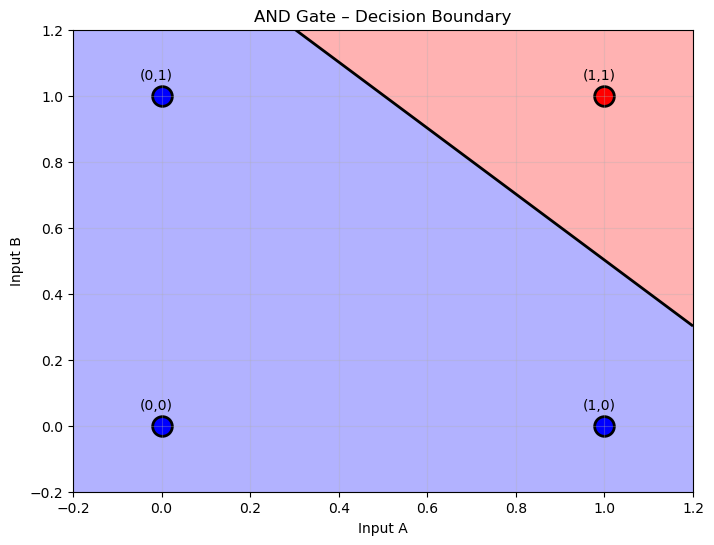

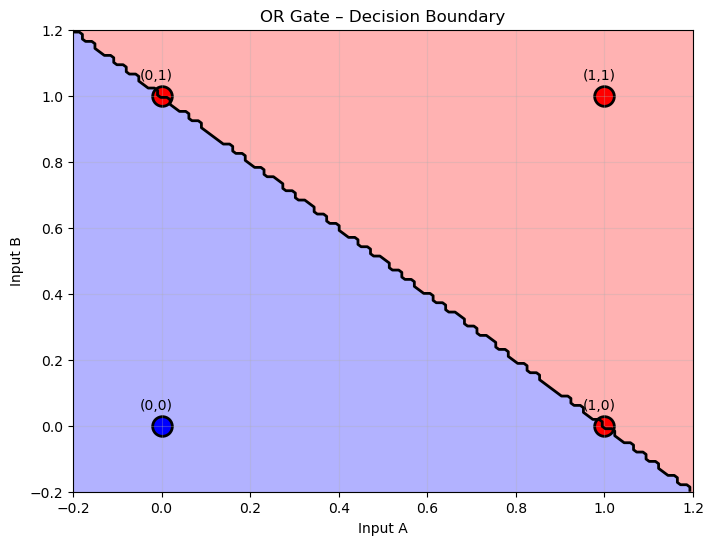

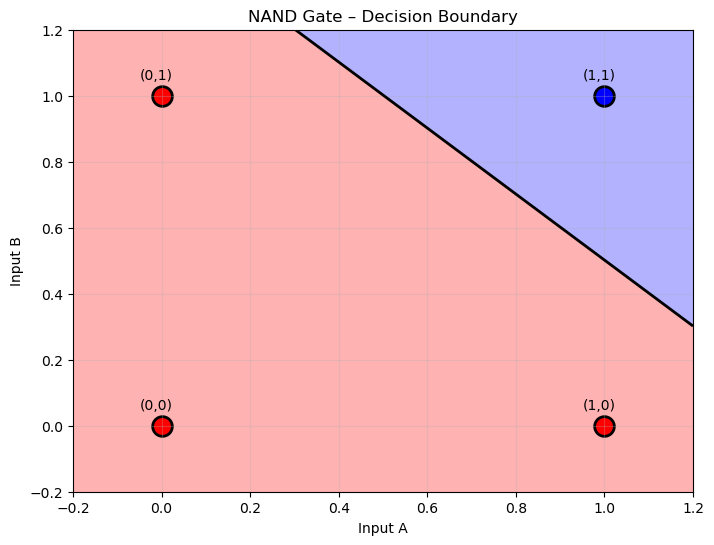

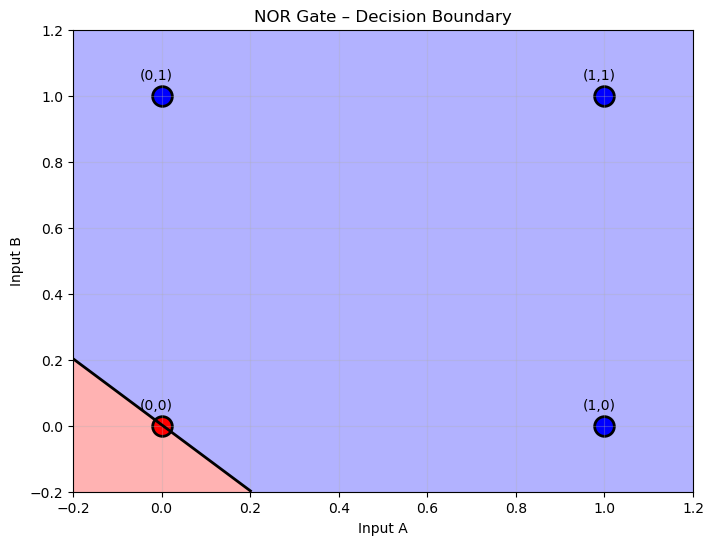

In [85]:
gates_to_plot = {
    "AND": and_gate(),
    "OR": or_gate(),
    "NAND": nand_gate(),
    "NOR": nor_gate()
}

for name, neuron in gates_to_plot.items():
    plot_gate_boundary(neuron, name)